# Energy-test grid search on the jax GPU backend

`LogLinearEnergyPT` with `backend='jax'` evaluates the whole parameter grid in a single jax process: every grid point's permutation energy test runs as batched matrix products on the GPU, with no worker processes. That engine change is what makes GPU-scale settings affordable — many permutations per point, a large synthetic sample at every grid point, and the full zoom-in refinement.

This notebook runs that configuration end to end. `fit_loglinear_energy.ipynb` tours both energy optimizers and both grid backends at smoke-test scale.

In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from raddest.api.flowvi import FlowVI
from raddest.api.fitter import LogLinearEnergyPT
from raddest.transfer import NegLogPlus

## Mock data

The same log-linear model with heteroscedastic errors as in `fit_loglinear.ipynb`.

In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = np.random.uniform(0.1, 10, size=N)
y = 10 ** (k * np.log10(x) + b + np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)
y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

In [ ]:
# each grid point compares a synthetic sample against the observed 2D
# sample; on the GPU backend both can be large
idx = np.random.choice(N, 4000, replace=False)
x_obs_fit, y_obs_fit = x_obs[idx], y_obs[idx]

Text(0, 0.5, 'y')

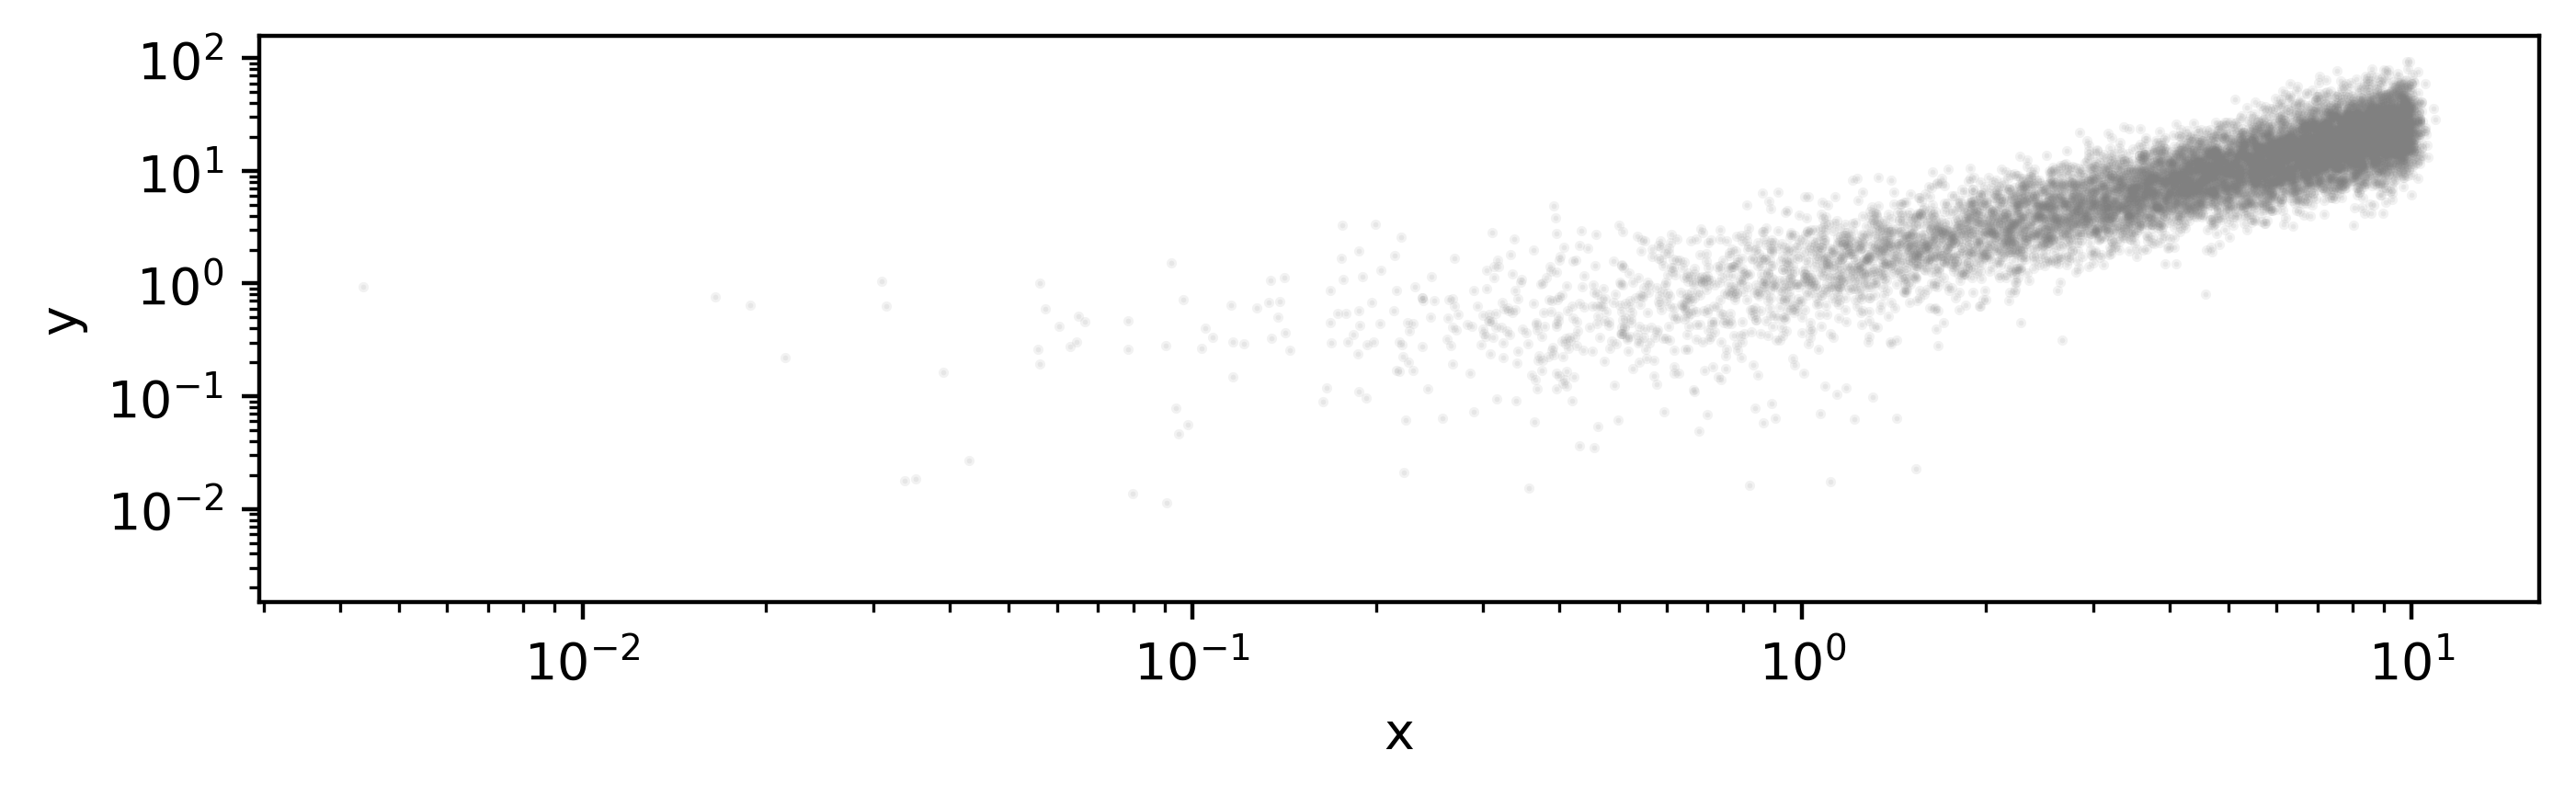

In [ ]:
plt.figure(figsize=(8, 2), dpi=400)
plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.1)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('x')
plt.ylabel('y')

## Fit p(x, x_err) and p(y, y_err)

In [ ]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

2026-11-24 19:53:22.700610: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:06<10:39,  6.46s/it]

  7%|▋         | 7/100 [00:06<01:04,  1.45it/s]

 14%|█▍        | 14/100 [00:06<00:24,  3.49it/s]

 21%|██        | 21/100 [00:06<00:12,  6.19it/s]

... (13 outputs left out)

step 10: loss 1.4334971904754639


step 20: loss 1.4276437759399414
step 30: loss 1.4242804050445557


step 40: loss 1.422835111618042
step 50: loss 1.4224144220352173


step 60: loss 1.4203513860702515


In [ ]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:08<14:44,  8.93s/it]

  7%|▋         | 7/100 [00:09<01:28,  1.05it/s]

 13%|█▎        | 13/100 [00:09<00:37,  2.34it/s]

 19%|█▉        | 19/100 [00:09<00:19,  4.06it/s]

 25%|██▌       | 25/100 [00:09<00:11,  6.34it/s]

... (14 outputs left out)

step 0: loss 2.6295506954193115
step 10: loss 2.6159329414367676


step 20: loss 2.6128108501434326
step 30: loss 2.6088881492614746


step 40: loss 2.6067042350769043
step 50: loss 2.605560779571533


step 60: loss 2.604294776916504


## Energy-test grid search at GPU scale

200 permutations per grid point and a 2000-point synthetic sample at every point, through the full zoom-in loop (`max_i=2`) plus refinement — the setting the numpy backend (one worker process per point) cannot reasonably reach. Cross-backend parity of the two engines is pinned by `test/test_energy.py` and `test/test_energy_regressors.py`.

Note what the numbers show: at this sample size the energy test is powerful enough that most of the grid is rejected (p-values near the floor), so the p-weighted mean tracks the good region coarsely and `sig` sits above the truth — a property of the strategy at GPU scale, identical on both backends. The point of the jax engine is the scale it affords; `LogLinearEnergyGrad` (see `fit_loglinear_energy.ipynb`) recovers tighter parameters when that is the goal.

In [ ]:
regressor_pt_jax = LogLinearEnergyPT(xflow, yflow, permutations=200, backend='jax')

params_list = [
    np.linspace(0.5, 2.0, 5),
    np.linspace(-0.5, 0.6, 5),
    np.linspace(0.05, 0.4, 3),
]

%time params_mean, params_std, res_arr = regressor_pt_jax.fit(x_obs_fit, y_obs_fit, params_list=params_list, N=2000, max_i=2, refine=True, gen_new_grid_refine_kwargs={'n': 4})
print('energy-PT (jax, GPU) fitted:', *params_mean)
print('uncertainty:', *params_std)
print('Truth:', k, b, sig)

CPU times: user 8.57 s, sys: 1.33 s, total: 9.9 s
Wall time: 12.6 s
energy-PT (jax, GPU) fitted: 1.249999999999997 0.04999999999999983 0.3309028026526164
uncertainty: 1.2883353430315618 0.9447792515564787 0.24664038689214934
Truth: 1.3 0.1 0.2


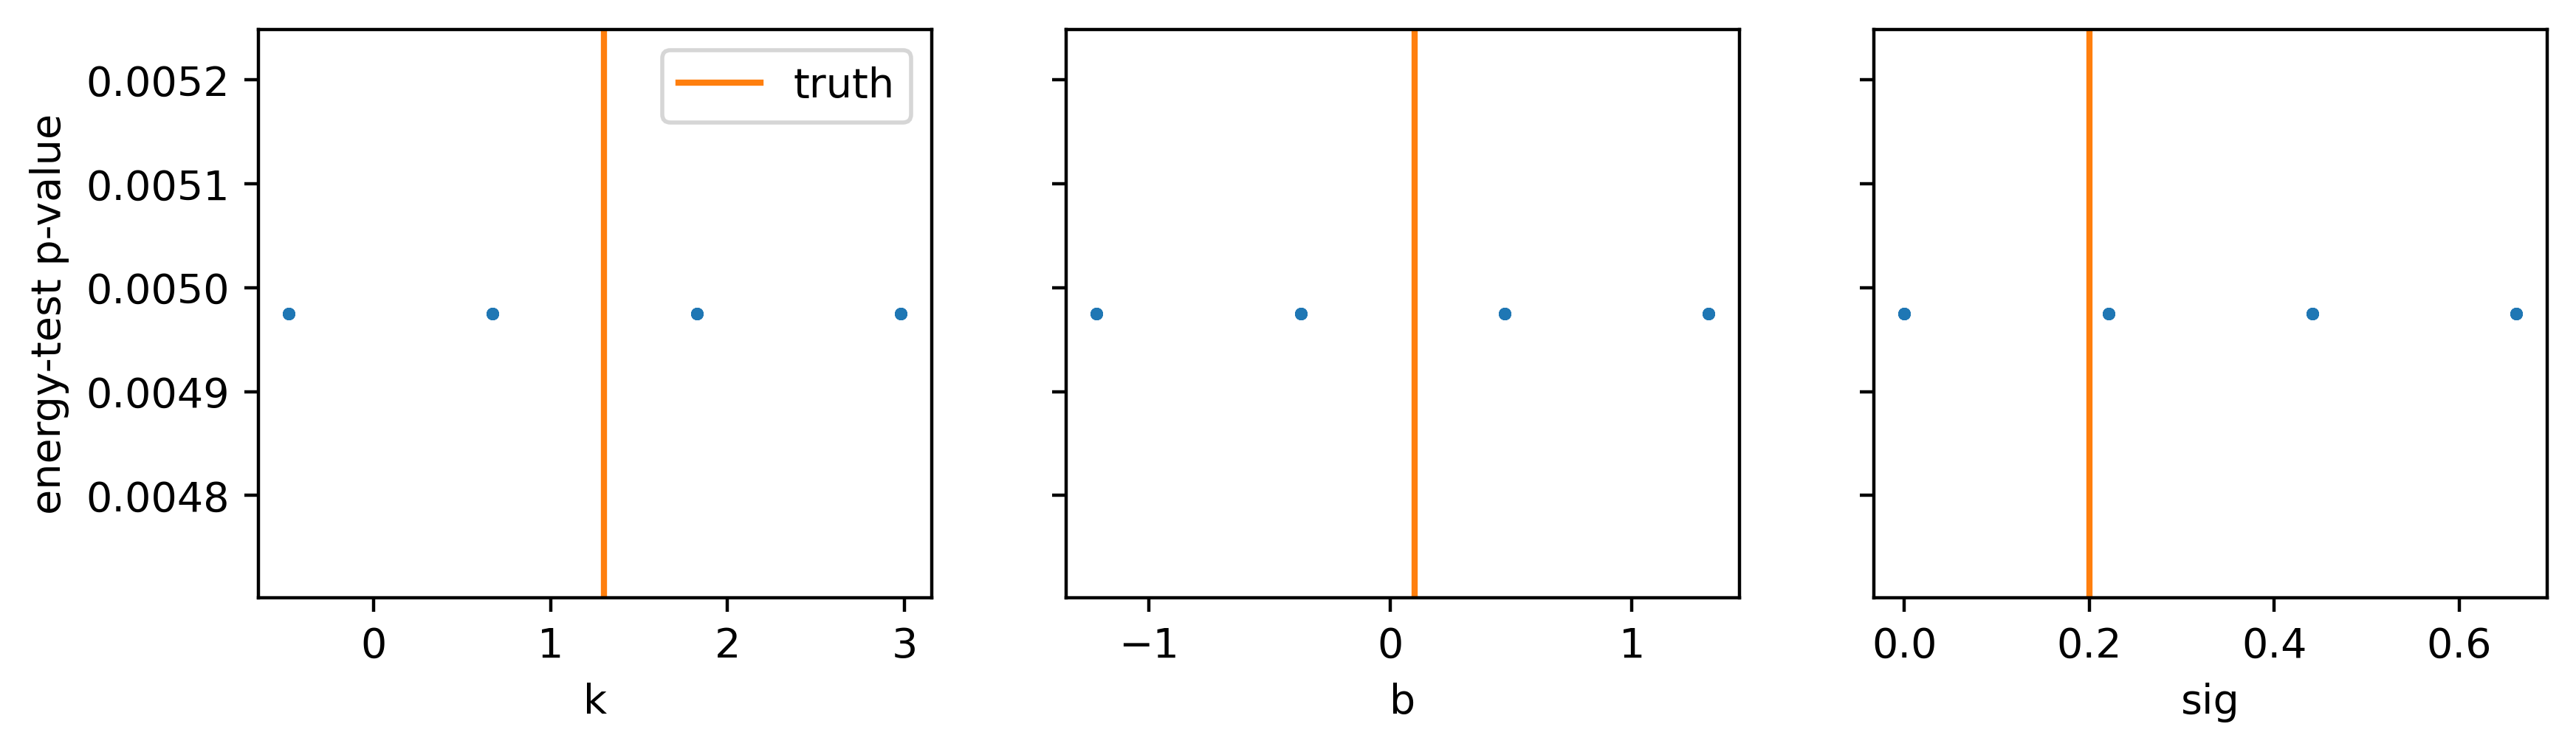

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.5), dpi=400, sharey=True)
for i, ax in enumerate(axes):
    ax.scatter(res_arr[:, i], res_arr[:, 4], s=4, alpha=0.4)
    ax.axvline([k, b, sig][i], color='C1', label='truth')
    ax.set_xlabel(['k', 'b', 'sig'][i])
axes[0].set_ylabel('energy-test p-value')
axes[0].legend()

## Goodness of fit

The energy test itself: a good parameter set gives a large p-value, a bad one the smallest possible.

In [ ]:
# the test is powerful: with thousands of points it detects even the
# slight misfit of the fitted parameters, so compare at the true
# parameters instead — a model that generated the data cannot be
# rejected, while clearly wrong parameters hit the p-value floor
params_true = np.array([k, b, sig])
_, p_true = regressor_pt_jax.energy_test(params_true, x_obs, y_obs, N=500, M=2000, permutations=200)
_, p_bad = regressor_pt_jax.energy_test(np.array([3.0, 1.0, 0.5]), x_obs, y_obs, N=500, M=2000, permutations=200)
print(f'p-value at the true parameters: {p_true:.3f}')
print(f'p-value at clearly wrong parameters: {p_bad:.3f}')

p-value at the true parameters: 0.050
p-value at clearly wrong parameters: 0.005


## Fitted model vs data

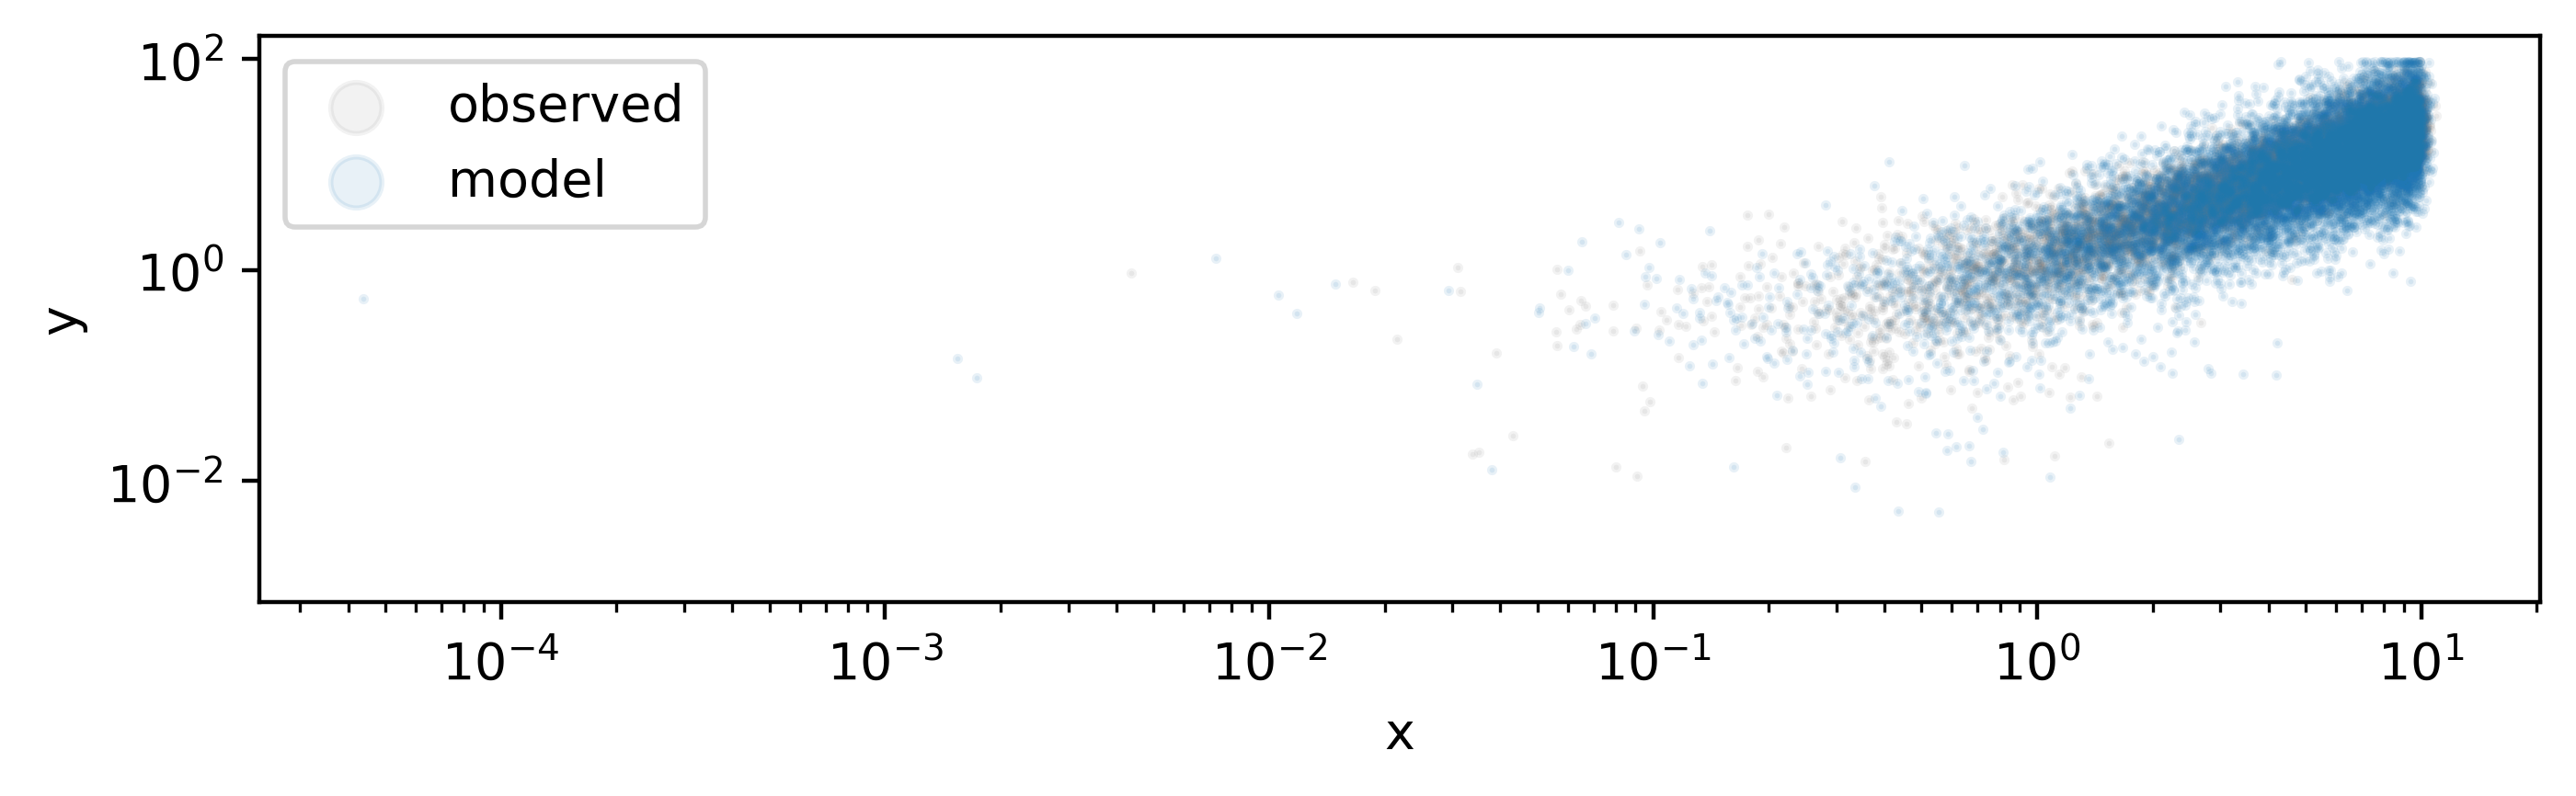

In [ ]:
params_fit = np.asarray(params_mean)
x_obs_gen, y_obs_gen, _, _, x_gen, _ = regressor_pt_jax.sample(params_fit, N=10000)

plt.figure(figsize=(8, 2), dpi=400)
plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.1, label='observed')
plt.scatter(x_obs_gen, y_obs_gen, s=1, color='C0', alpha=0.1, label='model')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('x')
plt.ylabel('y')
plt.legend(markerscale=10)